# NFL Big Data Bowl 2027: Forty Timers vs Tracking

## Cohort

The frozen roster contains 510 players / 510 unique nfl_id. The player-level report has 1/418 players with no timed 40-yard attempt, so their selected-attempt fields are blank.

In [1]:
import os
from base64 import b64encode
from datetime import datetime
from math import hypot
from pathlib import Path
from statistics import correlation
from struct import unpack
from time import perf_counter
from zlib import crc32

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

slug = "nfl-big-data-bowl-2027"
kaggle_input = Path("/kaggle/input")
on_kaggle = kaggle_input.is_dir()
mounted_players = next(kaggle_input.rglob("players.csv"), None) if on_kaggle else None
candidates = (Path("nfl-bdb2027") / slug, Path("data"))
raw = mounted_players.parent if mounted_players else next(
    (path for path in candidates if (path / "players.csv").is_file()), None
)
if raw is None:
    raise FileNotFoundError(f"players.csv not found under {kaggle_input} or {candidates}")
print("Resolved data directory:", raw.resolve())
print("CSV files:", ", ".join(sorted(path.name for path in raw.glob("*.csv"))))
figures = Path(".") if on_kaggle else Path(os.environ.get("NFL_KAGGLE_STAGE", ".")) / "figures_kaggle"
if figures.is_absolute():
    raise ValueError("Output path must be relative.")
figures.mkdir(exist_ok=True)
results = pl.read_csv(raw / "combine_results.csv", null_values="NA")
official = results.select("nfl_id", "draft_year", "forty")
players = pl.read_csv(raw / "players.csv", columns=["nfl_id"])
print(f"Input: {raw} | Output: {figures}")
print(f"Polars {pl.__version__} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")

Input: nfl-bdb2027\nfl-big-data-bowl-2027 | Output: .kaggle_verify_ztn9goep\figures_kaggle
Polars 2.1.0 | NumPy 2.5.5 | Matplotlib 3.11.2


## Clock method

The frozen Method v2 uses clock onset at 1.5 yd/s (three sustained frames), extrapolation flagged, median absolute error 0.0593 s, crossing coverage 789/793. Both clocks measure distance along the first-to-last axis from the first frame, and the baseline times only observed crossings.

In [2]:
CLOCK_THRESHOLDS = (None, 1.5)

ATTEMPT_KEY = ["draft_year", "event_id", "nfl_id", "drill_name", "attempt"]

SPLIT_COLUMNS = [f"time_{yards}yd_s" for yards in (10, 20, 30, 40)]

def extract_attempt_features(
    frames: list[tuple[float, float, float, float, float]],
    *,
    onset_threshold: float | None = None,
    extrapolate: bool = False,
) -> dict[str, float | bool | None]:
    """Accept (time in s, x, y, s, a) frames for one attempt."""
    times, xs, ys, speeds, accelerations = zip(*sorted(frames))
    if any(later <= earlier for earlier, later in zip(times, times[1:])):
        raise ValueError("Each attempt must have distinct frame timestamps.")
    onset = 0 if onset_threshold is None else next(
        (i for i in range(len(speeds) - 2) if min(speeds[i:i + 3]) > onset_threshold),
        None,
    )
    # Changing the clock does not change the coordinates or the crossing position.
    elapsed = [time - times[onset or 0] for time in times]
    dx, dy = xs[-1] - xs[0], ys[-1] - ys[0]
    span = hypot(dx, dy)
    progress = (
        [((x - xs[0]) * dx + (y - ys[0]) * dy) / span for x, y in zip(xs, ys)]
        if span
        else [0.0] * len(times)
    )

    def early_mean(window: float) -> float | None:
        if onset is None or elapsed[-1] < window:
            return None
        area = 0.0
        for i in range(onset, len(elapsed) - 1):
            start, end = elapsed[i:i + 2]
            width = min(end, window) - start
            left = accelerations[i]
            right = left + (accelerations[i + 1] - left) * width / (end - start)
            area += (left + right) * width / 2
            if end >= window:
                break
        return area / window

    features = dict.fromkeys(SPLIT_COLUMNS)
    speed_at_40 = None
    for yards, column in zip((10, 20, 30, 40), SPLIT_COLUMNS):
        for i, (left, right) in enumerate(zip(progress, progress[1:])):
            if left < yards <= right:
                fraction = (yards - left) / (right - left)
                if onset is not None:
                    features[column] = elapsed[i] + fraction * (elapsed[i + 1] - elapsed[i])
                if yards == 40:
                    speed_at_40 = speeds[i] + fraction * (speeds[i + 1] - speeds[i])
                break
    recovered = (
        extrapolate and onset is not None and features["time_40yd_s"] is None
        and 39 <= max(progress) < 40 and speeds[-1] > 0
    )
    if recovered:
        features["time_40yd_s"] = elapsed[-1] + (40 - progress[-1]) / speeds[-1]
        speed_at_40 = speeds[-1]
    return {
        **features,
        "extrapolated": recovered,
        "max_s_yd_s": max(speeds),
        "mean_a_first_0_5s_yd_s2": early_mean(0.5),
        "mean_a_first_1_0s_yd_s2": early_mean(1.0),
        "s_at_40yd_yd_s": speed_at_40,
    }

def build_features(source: Path) -> dict[float | None, pl.DataFrame]:
    frames = (
        pl.scan_csv(source / "combine_tracking.csv", null_values="NA")
        .filter((pl.col("drill_type") == "FORTY_YARD_DASH") & (pl.col("entity_type") == "PLAYER"))
        .select(*ATTEMPT_KEY, "time", "x", "y", "s", "a")
        .collect(engine="streaming")
    )
    if not frames.height or any(frames.null_count().row(0)):
        raise ValueError("Expected complete PLAYER forty tracking records.")
    rows = {threshold: [] for threshold in CLOCK_THRESHOLDS}
    for key, attempt in frames.partition_by(ATTEMPT_KEY, as_dict=True).items():
        ordered = attempt.sort("time").select("time", "x", "y", "s", "a")
        origin = datetime.fromisoformat(ordered["time"][0])
        measurements = [
            ((datetime.fromisoformat(time) - origin).total_seconds(), x, y, s, a)
            for time, x, y, s, a in ordered.iter_rows()
        ]
        for threshold in CLOCK_THRESHOLDS:
            features = extract_attempt_features(measurements, onset_threshold=threshold, extrapolate=threshold is not None)
            rows[threshold].append(dict(zip(ATTEMPT_KEY, key)) | features)
    feature_types = {name: pl.Float64 for name in [
        *SPLIT_COLUMNS, "max_s_yd_s", "mean_a_first_0_5s_yd_s2",
        "mean_a_first_1_0s_yd_s2", "s_at_40yd_yd_s",
    ]}
    return {
        threshold: pl.DataFrame(attempts, schema_overrides=feature_types).sort(ATTEMPT_KEY)
        for threshold, attempts in rows.items()
    }

features_by_clock = build_features(raw)
baseline, attempts = features_by_clock[None], features_by_clock[1.5]

def validation(df):
    return (df.join(official,on=["nfl_id","draft_year"],validate="m:1")
            .drop_nulls(["time_40yd_s","forty"])
            .with_columns(error=pl.col("time_40yd_s")-pl.col("forty")))
old,new=validation(baseline),validation(attempts)
observed=new.filter(~pl.col("extrapolated"))

## Forty timers vs tracking

The frozen starts-per-season Spearman correlations are -0.079 (n=417) for derived 10-yard time and -0.070 (n=417) for derived forty time. The official forty correlation is -0.049 (n=418).

In [3]:
FEATURES = [
    "time_10yd_s", "time_20yd_s", "time_40yd_s", "max_s_yd_s",
    "mean_a_first_0_5s_yd_s2", "mean_a_first_1_0s_yd_s2", "s_at_40yd_yd_s",
    "forty", "ten_yd_split",
]

SPEED_OUTCOMES = ["player_play_mean_top_speed", "player_play_max_top_speed"]

OUTCOMES = [
    "games_played_per_season", "games_started_per_season", "pro_bowls", "all_pros",
    "play_count", *SPEED_OUTCOMES,
]

PRIMARY = [
    ("time_10yd_s", "games_started_per_season"),
    ("max_s_yd_s", "player_play_max_top_speed"),
    ("time_40yd_s", "games_started_per_season"),
    ("forty", "games_started_per_season"),
]

def aggregate_players(
    attempts: pl.DataFrame, results: pl.DataFrame, career: pl.DataFrame, plays: pl.DataFrame,
) -> pl.DataFrame:
    fastest = (attempts.drop_nulls("time_40yd_s")
               .sort("nfl_id", "time_40yd_s", "event_id", "attempt")
               .unique(subset=["nfl_id"], keep="first", maintain_order=True))
    cohort = attempts.select("nfl_id", "draft_year").unique()
    return (
        cohort.join(fastest, on=["nfl_id", "draft_year"], how="left", validate="1:1")
        .join(results, on=["nfl_id", "draft_year"], how="left", validate="1:1")
        .join(career, on="nfl_id", how="left", validate="1:1")
        .join(plays, on="nfl_id", how="left", validate="1:1")
        .with_columns(seasons=2026 - pl.col("draft_year"))
        .with_columns(
            games_played_per_season=pl.col("career_games_active") / pl.col("seasons"),
            games_started_per_season=pl.col("career_games_started") / pl.col("seasons"),
            pro_bowls=pl.col("pro_bowl_original_ballot"),
            all_pros=pl.col("ap_all_pro_1st_team") + pl.col("ap_all_pro_2nd_team"),
        )
        .sort("nfl_id")
    )

def spearman(group: pl.DataFrame, feature: str, outcome: str) -> str:
    paired = group.select(feature, outcome).drop_nulls()
    x, y = paired[feature], paired[outcome]
    n = paired.height
    if n < 2 or x.n_unique() < 2 or y.n_unique() < 2:
        return f"NA (n={n})"
    rho = correlation(x.rank(method="average"), y.rank(method="average"))
    return f"{rho:.3f} (n={n})"

def report(players: pl.DataFrame, missing_play_all: int) -> str:
    groups = [("Overall", players)] + [
        (position, players.filter(pl.col("combine_position") == position))
        for position in sorted(players["combine_position"].unique())
    ]

    def table(pairs: list[tuple[str, str]]) -> str:
        header = ["Feature", "Outcome"] + [f"{label} ({g.height})" for label, g in groups]
        rows = [header, ["---"] * len(header)]
        rows.extend([f"`{x}`", f"`{y}`", *[spearman(g, x, y) for _, g in groups]] for x, y in pairs)
        return "\n".join("| " + " | ".join(row) + " |" for row in rows)

    secondary = [(x, y) for x in FEATURES for y in OUTCOMES if (x, y) not in PRIMARY]
    intro = (
        "# Player-level Spearman correlations\n\n"
        "Each cell gives Spearman rho and the pairwise complete player count. Tied values use average "
        "ranks. NA denotes too few pairs or a constant variable. Column headers give cohort sizes.\n\n"
        "The fastest derived 40-yard attempt supplies the tracking features. Ties use event ID and "
        f"attempt number. {players['attempt'].null_count()}/418 players had no timed 40-yard attempt "
        "and have blank selected-attempt fields. Games rates use career_games_active and career_games_started divided "
        "by 2026 minus draft year. Pro Bowls use the original ballot count and All-Pros sum AP first "
        "and second teams.\n\n"
        "The supplied player_play.csv has no recorded speed column. Mean and max top speed "
        "are missing for all players. Play count uses the number of supplied player-play rows. "
        f"{missing_play_all}/510 players had no player_play rows in the supplied data. "
        f"In the 418-player cohort, {players['play_count'].null_count()}/418 had no rows.\n"
    )
    return intro + "\n## Primary\n\n" + table(PRIMARY) + "\n\n## Secondary\n\n" + table(secondary) + "\n"

career=pl.read_csv(raw/"player_career_successes.csv",null_values="NA")
plays=(pl.scan_csv(raw/"player_play.csv",null_values="NA").select("nfl_id")
       .drop_nulls().group_by("nfl_id").len(name="play_count").collect(engine="streaming"))
missing_play=players.join(plays,on="nfl_id",how="anti").height
assert missing_play==13
cohort=aggregate_players(
    attempts.select("nfl_id","draft_year","event_id","attempt","extrapolated",*FEATURES[:-2]),
    results.select("nfl_id","draft_year","combine_position","forty","ten_yd_split"),
    career,plays,
).with_columns(pl.lit(None,dtype=pl.Float64).alias(c) for c in SPEED_OUTCOMES)
display({"text/markdown": report(cohort, missing_play)}, raw=True)

# Player-level Spearman correlations

Each cell gives Spearman rho and the pairwise complete player count. Tied values use average ranks. NA denotes too few pairs or a constant variable. Column headers give cohort sizes.

The fastest derived 40-yard attempt supplies the tracking features. Ties use event ID and attempt number. 1/418 players had no timed 40-yard attempt and have blank selected-attempt fields. Games rates use career_games_active and career_games_started divided by 2026 minus draft year. Pro Bowls use the original ballot count and All-Pros sum AP first and second teams.

The supplied player_play.csv has no recorded speed column. Mean and max top speed are missing for all players. Play count uses the number of supplied player-play rows. 13/510 players had no player_play rows in the supplied data. In the 418-player cohort, 11/418 had no rows.

## Primary

| Feature | Outcome | Overall (418) | DB (102) | DL (93) | OL (95) | TE (34) | WR (94) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| `time_10yd_s` | `games_started_per_season` | -0.079 (n=417) | -0.165 (n=102) | -0.104 (n=93) | -0.196 (n=94) | 0.012 (n=34) | -0.232 (n=94) |
| `max_s_yd_s` | `player_play_max_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `time_40yd_s` | `games_started_per_season` | -0.070 (n=417) | -0.160 (n=102) | -0.115 (n=93) | -0.303 (n=94) | 0.176 (n=34) | -0.268 (n=94) |
| `forty` | `games_started_per_season` | -0.049 (n=418) | -0.122 (n=102) | -0.060 (n=93) | -0.258 (n=95) | 0.152 (n=34) | -0.225 (n=94) |

## Secondary

| Feature | Outcome | Overall (418) | DB (102) | DL (93) | OL (95) | TE (34) | WR (94) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| `time_10yd_s` | `games_played_per_season` | -0.055 (n=417) | -0.109 (n=102) | -0.035 (n=93) | -0.103 (n=94) | -0.124 (n=34) | -0.054 (n=94) |
| `time_10yd_s` | `pro_bowls` | -0.036 (n=417) | 0.089 (n=102) | -0.075 (n=93) | -0.174 (n=94) | NA (n=34) | -0.031 (n=94) |
| `time_10yd_s` | `all_pros` | 0.022 (n=417) | 0.164 (n=102) | -0.031 (n=93) | 0.017 (n=94) | NA (n=34) | -0.033 (n=94) |
| `time_10yd_s` | `play_count` | -0.061 (n=406) | -0.215 (n=99) | -0.272 (n=90) | -0.306 (n=93) | -0.181 (n=31) | -0.300 (n=93) |
| `time_10yd_s` | `player_play_mean_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `time_10yd_s` | `player_play_max_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `time_20yd_s` | `games_played_per_season` | -0.069 (n=417) | -0.127 (n=102) | -0.076 (n=93) | -0.162 (n=94) | -0.054 (n=34) | -0.120 (n=94) |
| `time_20yd_s` | `games_started_per_season` | -0.074 (n=417) | -0.149 (n=102) | -0.127 (n=93) | -0.254 (n=94) | 0.146 (n=34) | -0.270 (n=94) |
| `time_20yd_s` | `pro_bowls` | -0.046 (n=417) | 0.113 (n=102) | -0.156 (n=93) | -0.174 (n=94) | NA (n=34) | -0.044 (n=94) |
| `time_20yd_s` | `all_pros` | -0.011 (n=417) | 0.154 (n=102) | -0.062 (n=93) | -0.029 (n=94) | NA (n=34) | -0.046 (n=94) |
| `time_20yd_s` | `play_count` | -0.018 (n=406) | -0.190 (n=99) | -0.273 (n=90) | -0.342 (n=93) | -0.154 (n=31) | -0.280 (n=93) |
| `time_20yd_s` | `player_play_mean_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `time_20yd_s` | `player_play_max_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `time_40yd_s` | `games_played_per_season` | -0.085 (n=417) | -0.151 (n=102) | -0.087 (n=93) | -0.199 (n=94) | -0.008 (n=34) | -0.233 (n=94) |
| `time_40yd_s` | `pro_bowls` | -0.067 (n=417) | 0.050 (n=102) | -0.222 (n=93) | -0.170 (n=94) | NA (n=34) | -0.077 (n=94) |
| `time_40yd_s` | `all_pros` | -0.043 (n=417) | 0.049 (n=102) | -0.082 (n=93) | -0.117 (n=94) | NA (n=34) | -0.079 (n=94) |
| `time_40yd_s` | `play_count` | 0.003 (n=406) | -0.198 (n=99) | -0.240 (n=90) | -0.354 (n=93) | -0.140 (n=31) | -0.229 (n=93) |
| `time_40yd_s` | `player_play_mean_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `time_40yd_s` | `player_play_max_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `max_s_yd_s` | `games_played_per_season` | 0.089 (n=417) | 0.143 (n=102) | 0.080 (n=93) | 0.206 (n=94) | 0.006 (n=34) | 0.314 (n=94) |
| `max_s_yd_s` | `games_started_per_season` | 0.052 (n=417) | 0.143 (n=102) | 0.059 (n=93) | 0.304 (n=94) | -0.111 (n=34) | 0.145 (n=94) |
| `max_s_yd_s` | `pro_bowls` | 0.097 (n=417) | 0.070 (n=102) | 0.241 (n=93) | 0.063 (n=94) | NA (n=34) | 0.087 (n=94) |
| `max_s_yd_s` | `all_pros` | 0.075 (n=417) | 0.161 (n=102) | 0.074 (n=93) | 0.170 (n=94) | NA (n=34) | 0.087 (n=94) |
| `max_s_yd_s` | `play_count` | -0.042 (n=406) | 0.122 (n=99) | 0.162 (n=90) | 0.284 (n=93) | 0.128 (n=31) | 0.081 (n=93) |
| `max_s_yd_s` | `player_play_mean_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `mean_a_first_0_5s_yd_s2` | `games_played_per_season` | 0.062 (n=417) | 0.152 (n=102) | 0.028 (n=93) | 0.041 (n=94) | 0.240 (n=34) | 0.011 (n=94) |
| `mean_a_first_0_5s_yd_s2` | `games_started_per_season` | 0.125 (n=417) | 0.183 (n=102) | 0.147 (n=93) | 0.180 (n=94) | 0.164 (n=34) | 0.199 (n=94) |
| `mean_a_first_0_5s_yd_s2` | `pro_bowls` | 0.034 (n=417) | -0.055 (n=102) | 0.038 (n=93) | 0.170 (n=94) | NA (n=34) | 0.037 (n=94) |
| `mean_a_first_0_5s_yd_s2` | `all_pros` | -0.010 (n=417) | -0.157 (n=102) | 0.054 (n=93) | 0.025 (n=94) | NA (n=34) | 0.038 (n=94) |
| `mean_a_first_0_5s_yd_s2` | `play_count` | 0.153 (n=406) | 0.268 (n=99) | 0.302 (n=90) | 0.270 (n=93) | 0.257 (n=31) | 0.301 (n=93) |
| `mean_a_first_0_5s_yd_s2` | `player_play_mean_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `mean_a_first_0_5s_yd_s2` | `player_play_max_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `mean_a_first_1_0s_yd_s2` | `games_played_per_season` | 0.065 (n=417) | 0.166 (n=102) | 0.043 (n=93) | -0.005 (n=94) | 0.143 (n=34) | 0.092 (n=94) |
| `mean_a_first_1_0s_yd_s2` | `games_started_per_season` | 0.118 (n=417) | 0.184 (n=102) | 0.174 (n=93) | 0.130 (n=94) | 0.056 (n=34) | 0.296 (n=94) |
| `mean_a_first_1_0s_yd_s2` | `pro_bowls` | 0.085 (n=417) | -0.043 (n=102) | 0.128 (n=93) | 0.170 (n=94) | NA (n=34) | 0.070 (n=94) |
| `mean_a_first_1_0s_yd_s2` | `all_pros` | 0.039 (n=417) | -0.066 (n=102) | 0.109 (n=93) | 0.032 (n=94) | NA (n=34) | 0.071 (n=94) |
| `mean_a_first_1_0s_yd_s2` | `play_count` | 0.106 (n=406) | 0.286 (n=99) | 0.311 (n=90) | 0.195 (n=93) | 0.241 (n=31) | 0.384 (n=93) |
| `mean_a_first_1_0s_yd_s2` | `player_play_mean_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `mean_a_first_1_0s_yd_s2` | `player_play_max_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `s_at_40yd_yd_s` | `games_played_per_season` | 0.092 (n=417) | 0.118 (n=102) | 0.097 (n=93) | 0.201 (n=94) | 0.083 (n=34) | 0.334 (n=94) |
| `s_at_40yd_yd_s` | `games_started_per_season` | 0.045 (n=417) | 0.110 (n=102) | 0.068 (n=93) | 0.250 (n=94) | -0.074 (n=34) | 0.138 (n=94) |
| `s_at_40yd_yd_s` | `pro_bowls` | 0.097 (n=417) | 0.070 (n=102) | 0.252 (n=93) | 0.006 (n=94) | NA (n=34) | 0.125 (n=94) |
| `s_at_40yd_yd_s` | `all_pros` | 0.081 (n=417) | 0.161 (n=102) | 0.089 (n=93) | 0.170 (n=94) | NA (n=34) | 0.125 (n=94) |
| `s_at_40yd_yd_s` | `play_count` | -0.043 (n=406) | 0.084 (n=99) | 0.183 (n=90) | 0.243 (n=93) | 0.102 (n=31) | 0.070 (n=93) |
| `s_at_40yd_yd_s` | `player_play_mean_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `s_at_40yd_yd_s` | `player_play_max_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `forty` | `games_played_per_season` | -0.103 (n=418) | -0.131 (n=102) | -0.094 (n=93) | -0.195 (n=95) | 0.026 (n=34) | -0.428 (n=94) |
| `forty` | `pro_bowls` | -0.101 (n=418) | -0.037 (n=102) | -0.258 (n=93) | -0.070 (n=95) | NA (n=34) | -0.206 (n=94) |
| `forty` | `all_pros` | -0.092 (n=418) | -0.162 (n=102) | -0.126 (n=93) | -0.117 (n=95) | NA (n=34) | -0.207 (n=94) |
| `forty` | `play_count` | 0.042 (n=407) | -0.112 (n=99) | -0.173 (n=90) | -0.220 (n=94) | -0.103 (n=31) | -0.105 (n=93) |
| `forty` | `player_play_mean_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `forty` | `player_play_max_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `ten_yd_split` | `games_played_per_season` | -0.072 (n=418) | -0.181 (n=102) | -0.131 (n=93) | -0.077 (n=95) | -0.116 (n=34) | -0.223 (n=94) |
| `ten_yd_split` | `games_started_per_season` | -0.052 (n=418) | -0.168 (n=102) | -0.055 (n=93) | -0.154 (n=95) | -0.055 (n=34) | -0.200 (n=94) |
| `ten_yd_split` | `pro_bowls` | -0.042 (n=418) | 0.007 (n=102) | -0.246 (n=93) | -0.121 (n=95) | NA (n=34) | -0.020 (n=94) |
| `ten_yd_split` | `all_pros` | -0.039 (n=418) | -0.087 (n=102) | -0.142 (n=93) | 0.077 (n=95) | NA (n=34) | -0.022 (n=94) |
| `ten_yd_split` | `play_count` | 0.063 (n=407) | -0.200 (n=99) | -0.164 (n=90) | -0.106 (n=94) | 0.029 (n=31) | -0.088 (n=93) |
| `ten_yd_split` | `player_play_mean_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |
| `ten_yd_split` | `player_play_max_top_speed` | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) | NA (n=0) |


## Speed transfer

The frozen player-play top-speed comparison is NA (n=0). Using supplied game tracking, the pooled association is higher for game p99 speed than for game maximum speed.

In [4]:
engine="CPU / Polars streaming"
t0=perf_counter()
scans=[pl.scan_csv(raw/f"game_tracking_{y}.csv",null_values="NA",
                   schema_overrides={"nfl_id":pl.Int64,"s":pl.Float64})
       .select("nfl_id","s","game_id","play_id") for y in (2023,2024,2025)]
game=(pl.concat(scans).join(players.lazy(),on="nfl_id",how="semi").group_by("nfl_id")
      .agg(pl.col("s").max().alias("game_max_s"),
           pl.col("s").quantile(.99,interpolation="linear").alias("game_p99_s"),
           pl.struct("game_id","play_id").n_unique().alias("game_plays"),
           pl.col("game_id").n_unique().alias("game_games")).collect(engine="streaming"))
print(f"GAME_STAGE_SECONDS={perf_counter()-t0:.3f} ({engine})")
cohort=cohort.join(game,on="nfl_id",how="left",validate="1:1").with_columns(
    plays_per_season=pl.col("game_plays")/pl.col("seasons"))
def rho(df,x,y):
    pair=df.select(x,y).drop_nulls()
    return correlation(pair[x].rank(method="average"),pair[y].rank(method="average")),pair.height
positions=["DB","DL","OL","TE","WR"]
groups={k:cohort.filter(pl.col("combine_position")==k) for k in positions}
speed_cols=["game_max_s","game_p99_s"]
speed={k:[rho(g,"max_s_yd_s",c) for c in speed_cols] for k,g in {"Pooled":cohort,**groups}.items()}

speed_table = ["| Group | Game max rho (n) | Game p99 rho (n) |", "|---|---:|---:|"]
for key, estimates in speed.items():
    maximum, upper = [f"{r:.3f} ({n})" for r,n in estimates]
    speed_table.append(f"| {key} | {maximum} | {upper} |")
display({"text/markdown": "\n".join(speed_table)}, raw=True)


GAME_STAGE_SECONDS=2.168 (CPU / Polars streaming)


| Group | Game max rho (n) | Game p99 rho (n) |
|---|---:|---:|
| Pooled | 0.810 (406) | 0.850 (406) |
| DB | 0.285 (99) | 0.289 (99) |
| DL | 0.652 (90) | 0.682 (90) |
| OL | 0.368 (93) | 0.141 (93) |
| TE | 0.625 (31) | 0.566 (31) |
| WR | 0.430 (93) | 0.539 (93) |

## Acceleration

The frozen starts-per-season association with mean acceleration over the first half-second is 0.125 (n=417). The frozen derived forty association with play count is 0.003 (n=406).

In [5]:
accel,starts="mean_a_first_0_5s_yd_s2","games_started_per_season"
def exclude(frame):
    return frame.filter(~pl.col("extrapolated").fill_null(False))
sensitivity=exclude(cohort)

## Limitations

In the frozen report, 13/510 players had no player_play rows in the supplied data. The validation uses a player-level official time, so multiple attempts can share it.

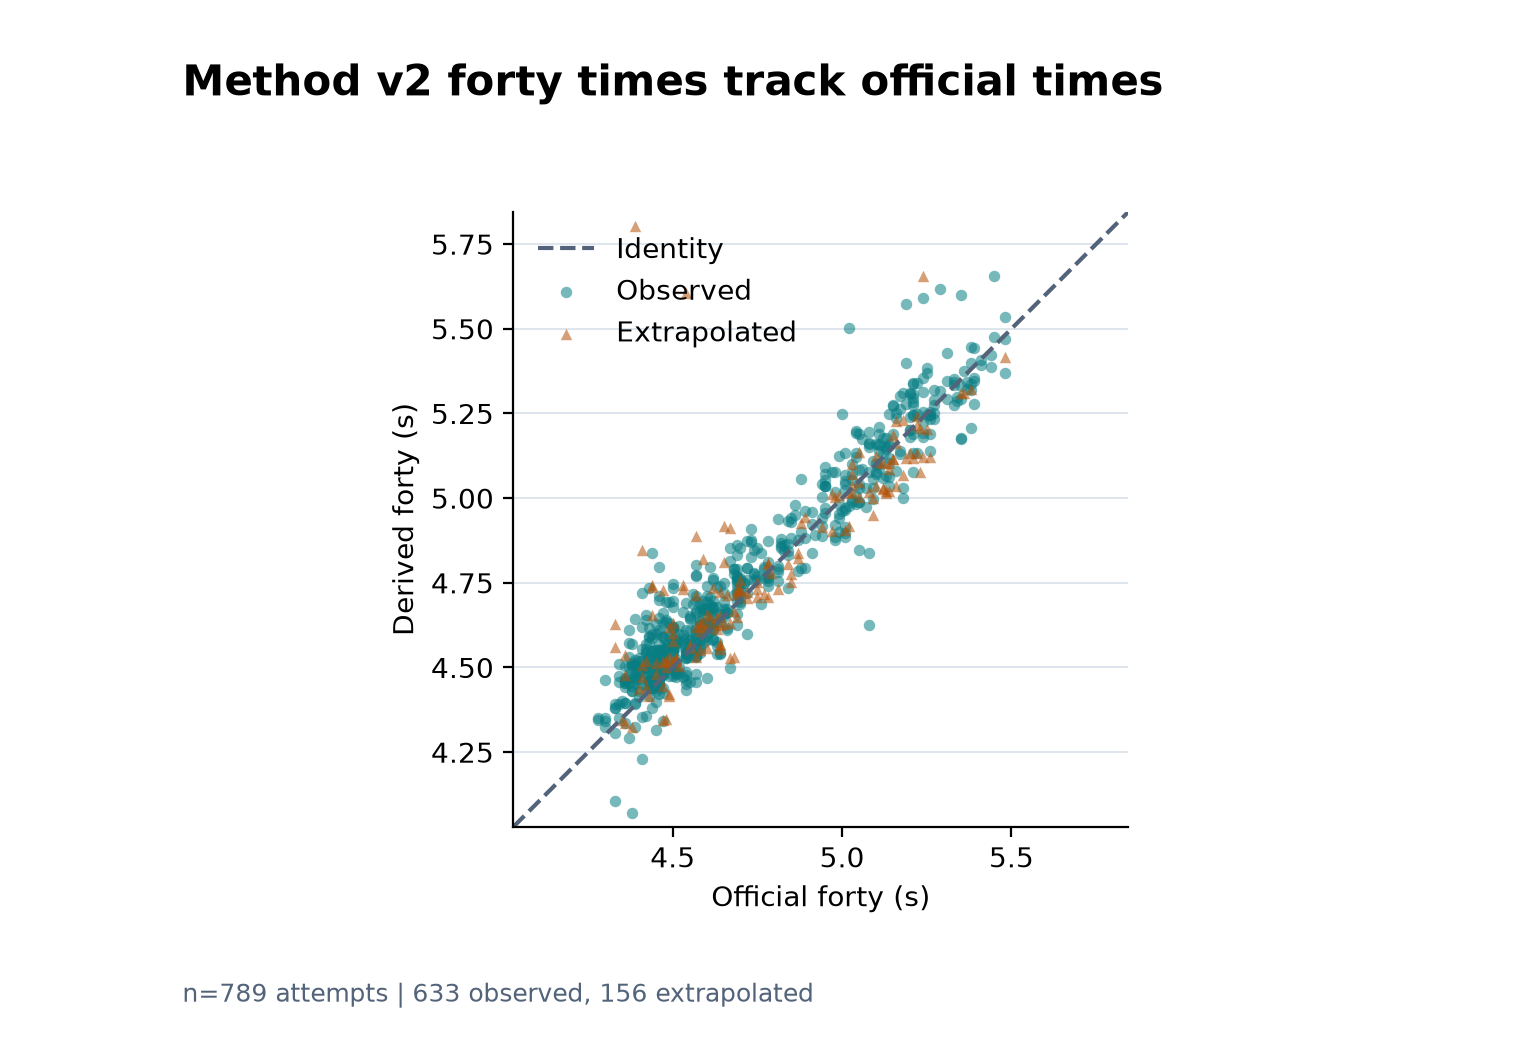

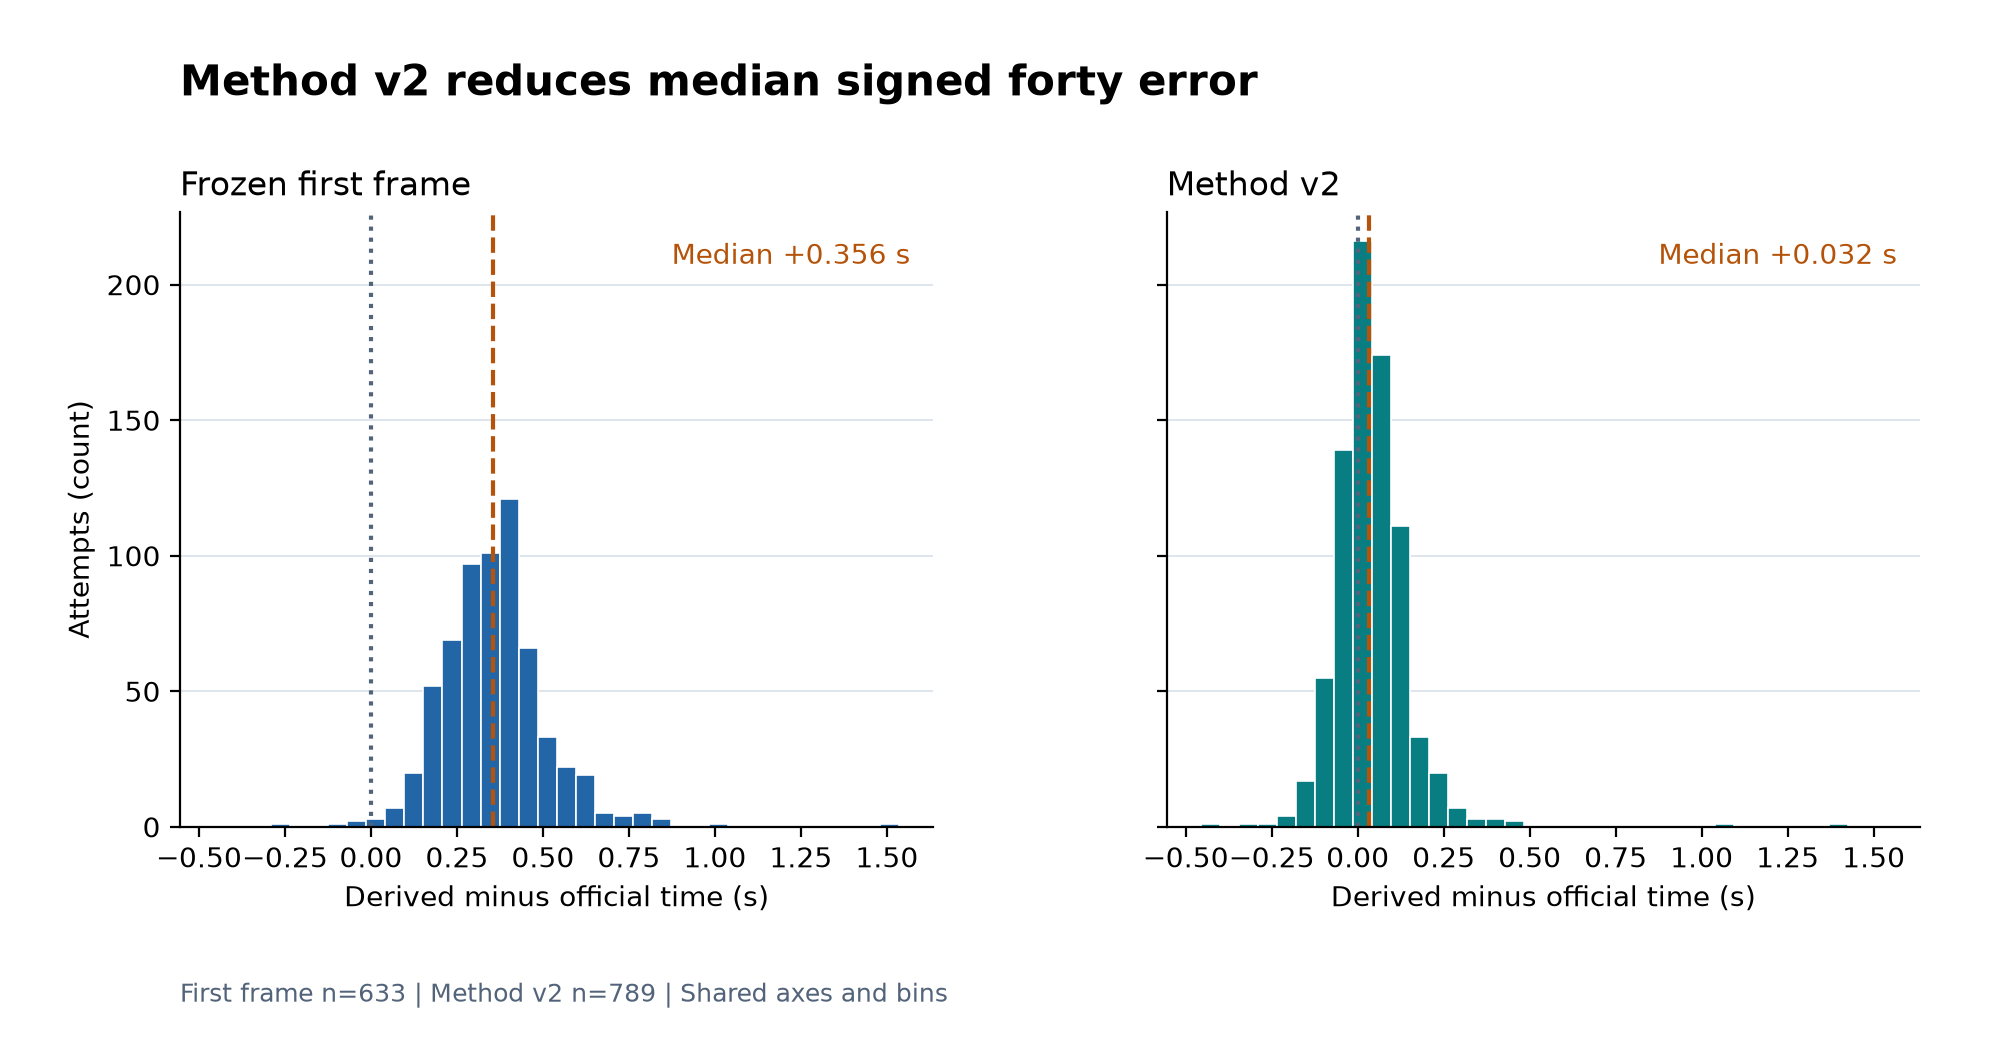

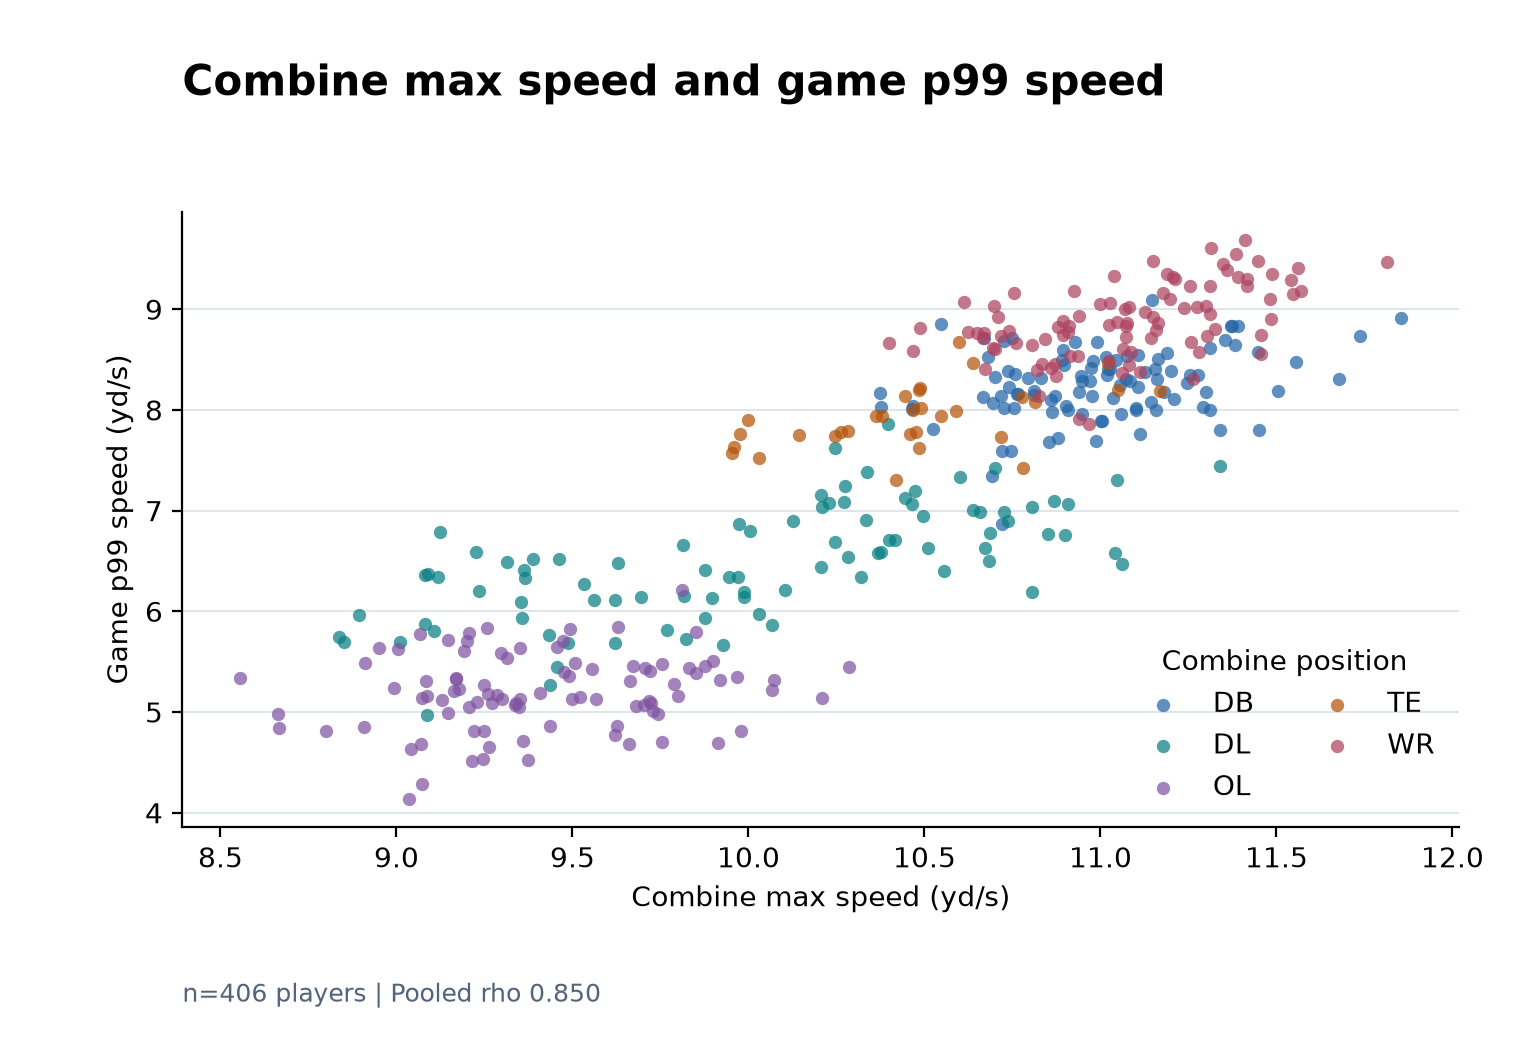

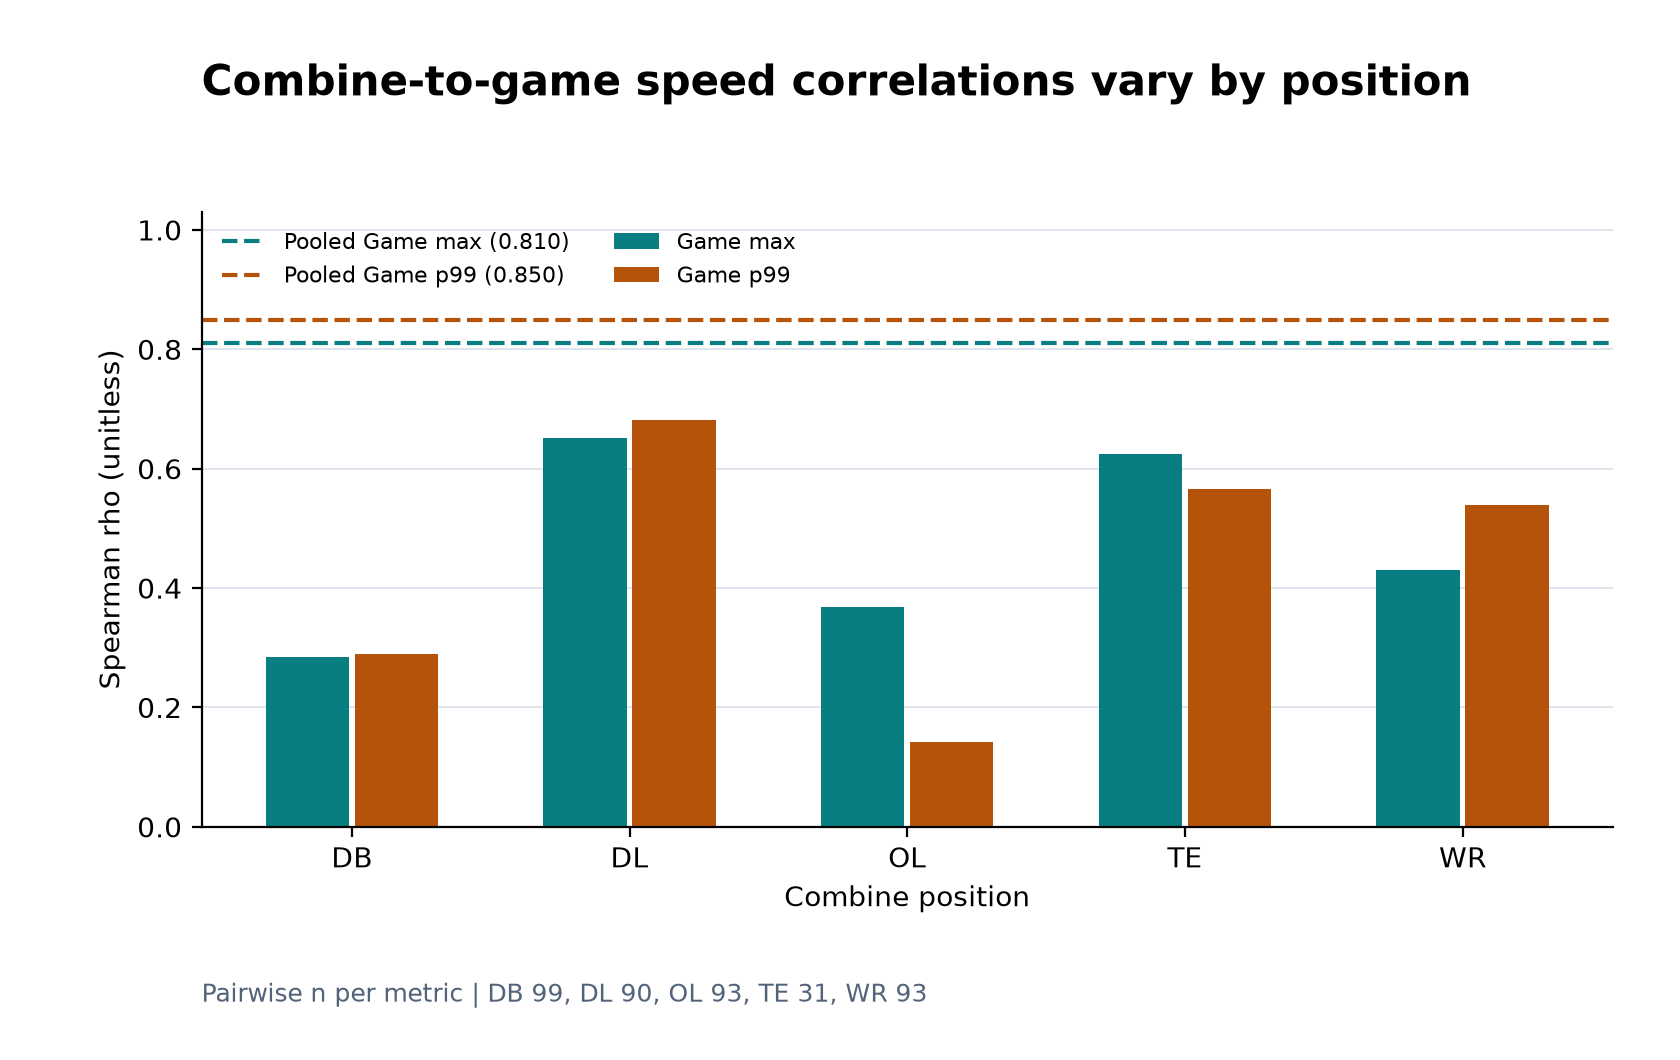

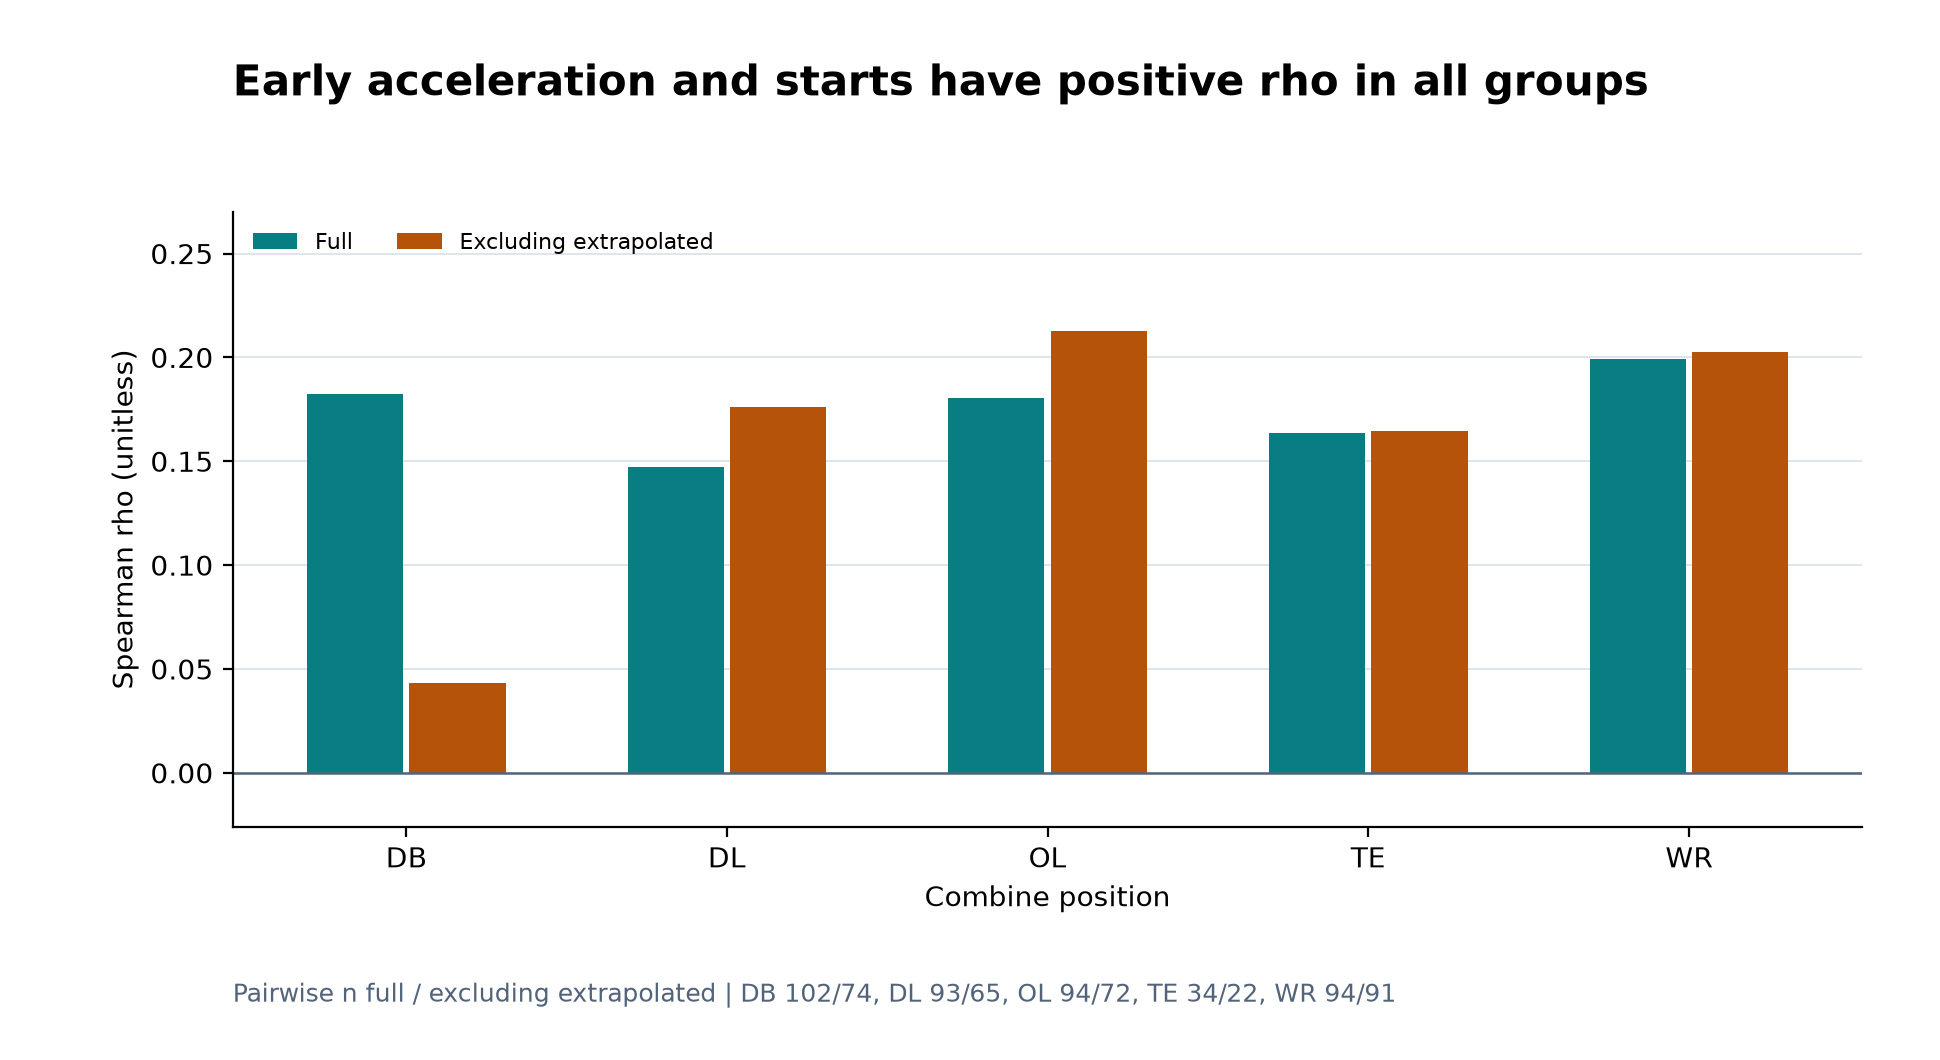

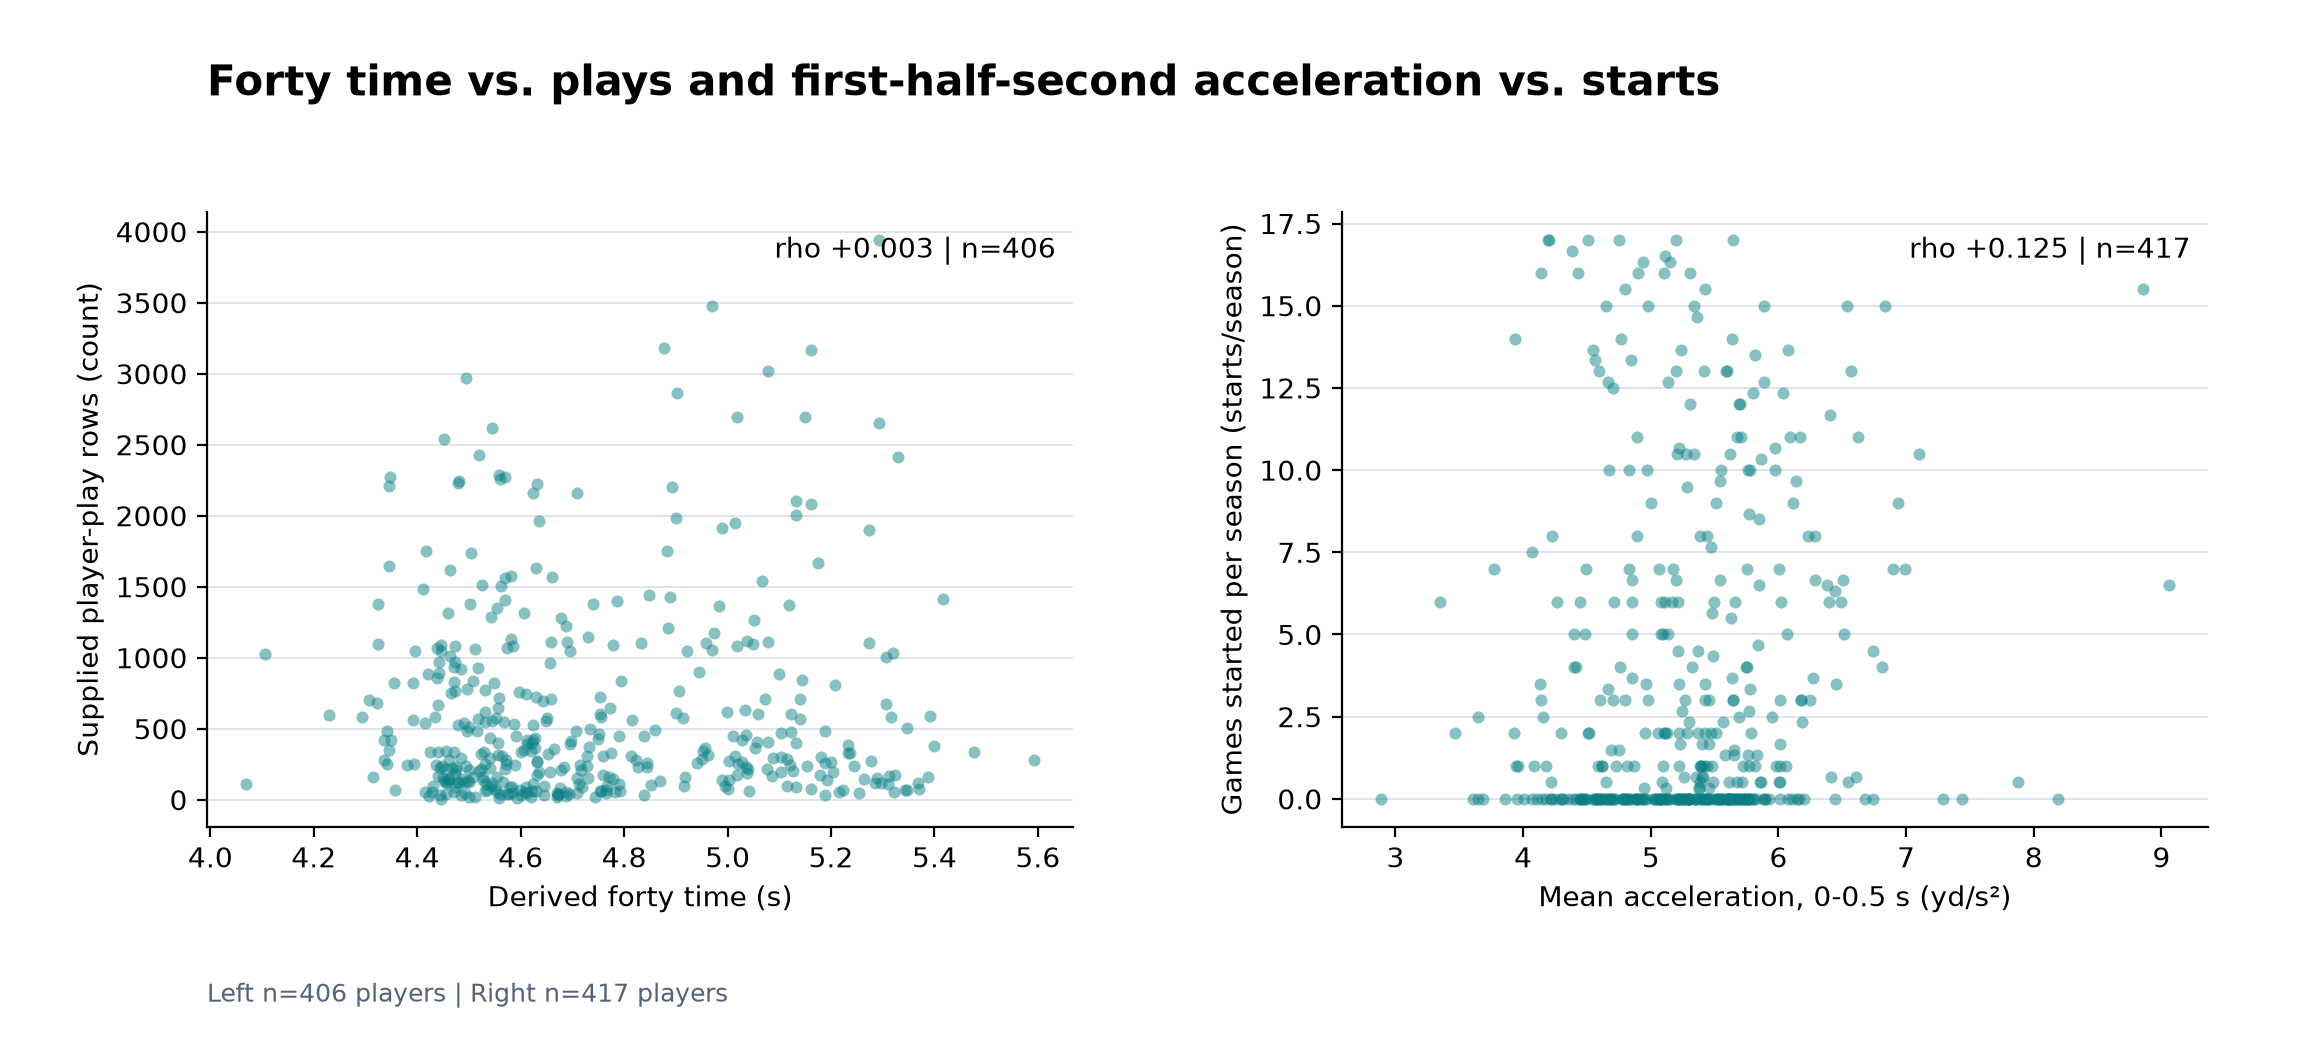

# Cohort and tracking coverage

| Draft class | Tracked n | Game-tracking n | Extrapolated n |
| --- | ---: | ---: | ---: |
| 2023 | 138 | 137 | 26 |
| 2024 | 147 | 145 | 53 |
| 2025 | 133 | 125 | 14 |
| **Total** | **418** | **407** | **93** |

Tracked n counts players with combine forty tracking. Game-tracking n counts players with supplied game tracking across the 2023–2025 seasons. Extrapolated n counts selected attempts flagged as extrapolated.


In [6]:
teal,amber,slate="#087E83","#B45309","#53647a"
colors=["#2366A8",teal,"#8054A1",amber,"#AD425F"]
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,
    "axes.axisbelow":True,"font.size":10,"legend.frameon":False})
def panels(title,width=7.6,count=1,**options):
    fig,axes=plt.subplots(1,count,figsize=(width,5.3),**options)
    fig.subplots_adjust(left=.12 if count==1 else .09,right=.96,bottom=.22,top=.80,wspace=.31)
    fig.text(fig.subplotpars.left,.91,title,fontsize=15,fontweight="bold")
    return fig,axes
def save(fig,name,caption):
    for ax in fig.axes:
        ax.grid(axis="y",color="#dee5ed",linewidth=.7)
    fig.text(fig.subplotpars.left,.055,caption,fontsize=9,color=slate)
    fig.savefig(figures/name,dpi=200)
    plt.close(fig)
    image = b64encode((figures / name).read_bytes()).decode("ascii")
    display({"image/png": image}, raw=True)
fig,ax=panels("Method v2 forty times track official times")
lo=min(new["forty"].min(),new["time_40yd_s"].min())-.04
hi=max(new["forty"].max(),new["time_40yd_s"].max())+.04
ax.plot([lo,hi],[lo,hi],"--",color=slate,label="Identity")
for flag,mark,color,label in [(False,"o",teal,"Observed"),(True,"^",amber,"Extrapolated")]:
    q=new.filter(pl.col("extrapolated")==flag)
    ax.scatter(q["forty"],q["time_40yd_s"],s=17,marker=mark,color=color,alpha=.55,linewidths=0,label=label)
ax.set(xlim=(lo,hi),ylim=(lo,hi),xlabel="Official forty (s)",ylabel="Derived forty (s)")
ax.set_aspect("equal")
ax.legend(loc="upper left")
save(fig,"fig1_validation_scatter.png",f"n={new.height} attempts | {observed.height} observed, {new.height-observed.height} extrapolated")
fig,axes=panels("Method v2 reduces median signed forty error",10,2,sharex=True,sharey=True)
bins=np.histogram_bin_edges(np.concatenate([old["error"].to_numpy(),new["error"].to_numpy()]),bins=36)
for ax,data,title,color in zip(axes,[old,new],["Frozen first frame","Method v2"],[colors[0],teal]):
    med=data["error"].median()
    ax.hist(data["error"].to_numpy(),bins=bins,color=color,edgecolor="white",linewidth=.6)
    ax.axvline(0,color=slate,ls=":")
    ax.axvline(med,color=amber,ls="--")
    ax.text(.97,.95,f"Median {med:+.3f} s",transform=ax.transAxes,ha="right",va="top",color=amber)
    ax.set_title(title,loc="left")
    ax.set_xlabel("Derived minus official time (s)")
axes[0].set_ylabel("Attempts (count)")
save(fig,"fig2_error_fix.png",f"First frame n={old.height} | Method v2 n={new.height} | Shared axes and bins")

fig,ax=panels("Combine max speed and game p99 speed")
for (k,g),color in zip(groups.items(),colors):
    q=g.select("max_s_yd_s","game_p99_s").drop_nulls()
    ax.scatter(q["max_s_yd_s"],q["game_p99_s"],s=23,color=color,alpha=.72,linewidths=0,label=k)
ax.set(xlabel="Combine max speed (yd/s)",ylabel="Game p99 speed (yd/s)")
ax.legend(title="Combine position",loc="lower right",ncol=2)
save(fig,"fig3_speed_transfer_scatter.png",f"n={speed['Pooled'][1][1]} players | Pooled rho {speed['Pooled'][1][0]:.3f}")

def bars(title,width,series,labels,filename,caption,limits,references=None):
    fig,ax=panels(title,width)
    index=np.arange(len(positions))
    for i,(label,color) in enumerate(zip(labels,[teal,amber])):
        ax.bar(index+(i-.5)*.32,[r for r,n in series[i]],.30,label=label,color=color)
        if references:
            ax.axhline(references[i],ls="--",color=color,label=f"Pooled {label} ({references[i]:.3f})")
    ax.axhline(0,color=slate,lw=.9)
    ax.set(xticks=index,xticklabels=positions,xlabel="Combine position",ylabel="Spearman rho (unitless)",ylim=limits)
    ax.legend(ncol=2,loc="upper left",fontsize=8)
    save(fig,filename,caption)
bars("Combine-to-game speed correlations vary by position",8.4,
     [[speed[k][i] for k in positions] for i in range(2)],["Game max","Game p99"],
     "fig4_speed_transfer_bars.png","Pairwise n per metric | "+", ".join(f"{k} {speed[k][0][1]}" for k in positions),
     (0,1.03),[r for r,n in speed["Pooled"]])
acceleration=[[rho(g,accel,starts) for g in groups.values()],
              [rho(exclude(g),accel,starts) for g in groups.values()]]
bars("Early acceleration and starts have positive rho in all groups",9.7,acceleration,
     ["Full","Excluding extrapolated"],"fig5_accel_starts_bars.png",
     "Pairwise n full / excluding extrapolated | "+", ".join(f"{k} {acceleration[0][i][1]}/{acceleration[1][i][1]}" for i,k in enumerate(positions)),
     (-.026,.27))
fig,axes=panels("Forty time vs. plays and first-half-second acceleration vs. starts",11.5,2)
ns=[]
for ax,x,y,xl,yl in [
    (axes[0],"time_40yd_s","play_count","Derived forty time (s)","Supplied player-play rows (count)"),
    (axes[1],accel,starts,"Mean acceleration, 0-0.5 s (yd/s\u00b2)","Games started per season (starts/season)")]:
    q=cohort.select(x,y).drop_nulls()
    r,n=rho(cohort,x,y)
    ns.append(n)
    ax.scatter(q[x],q[y],s=19,alpha=.48,color=teal,linewidths=0)
    ax.set(xlabel=xl,ylabel=yl)
    ax.text(.98,.96,f"rho {r:+.3f} | n={n}",transform=ax.transAxes,ha="right",va="top")
save(fig,"fig6_first_half_second.png",f"Left n={ns[0]} players | Right n={ns[1]} players")
classes=cohort.group_by("draft_year").agg(pl.len(),pl.col("game_games").count(),pl.col("extrapolated").sum()).sort("draft_year")
lines=["# Cohort and tracking coverage","","| Draft class | Tracked n | Game-tracking n | Extrapolated n |",
       "| --- | ---: | ---: | ---: |",*[f"| {y} | {n} | {g} | {e} |" for y,n,g,e in classes.rows()],
       f"| **Total** | **{cohort.height}** | **{cohort['game_games'].count()}** | **{cohort['extrapolated'].sum()}** |","",
       "Tracked n counts players with combine forty tracking. Game-tracking n counts players with supplied game tracking across the 2023\u20132025 seasons. Extrapolated n counts selected attempts flagged as extrapolated.",""]
(figures/"table1_cohort.md").write_text("\n".join(lines),encoding="utf-8")
display({"text/markdown": (figures / "table1_cohort.md").read_text(encoding="utf-8")}, raw=True)

In [7]:
def read_png_dpi(path):
    # Check PNG chunk CRCs and read both physical axes.
    with path.open("rb") as file:
        if file.read(8) != b"\x89PNG\r\n\x1a\n":
            raise ValueError(f"Invalid PNG: {path}")
        density = None
        while True:
            header = file.read(8)
            if len(header) != 8:
                raise ValueError(f"Incomplete PNG: {path}")
            size, kind = unpack(">I4s", header)
            data, checksum = file.read(size), file.read(4)
            if len(data) != size or len(checksum) != 4 or unpack(">I", checksum)[0] != crc32(kind + data):
                raise ValueError(f"Invalid PNG chunk: {path}")
            if kind == b"pHYs":
                x, y, unit = unpack(">IIB", data)
                if unit == 1:
                    density = (x * .0254, y * .0254)
            if kind == b"IEND":
                return density or (0, 0)

checks=[]
def add(label,v,t,tol=0,backend="CPU"):
    checks.append((label,v,t,tol,backend,abs(v-t)<=tol))
for name,df,n,r,mae in [("Method v2",new,789,.932,.0593),("Observed v2",observed,633,.9571,.0607),("Baseline",old,633,.889,.356)]:
    add(name+" n",df.height,n)
    add(name+" Pearson r",correlation(df["forty"],df["time_40yd_s"]),r,.002)
    add(name+" median abs error (s)",df["error"].abs().median(),mae,.002)
add("Baseline signed median (s)",old["error"].median(),.356,.002)
add("Tracked players",cohort["nfl_id"].n_unique(),418)
add("Attempts",attempts.height,793)
add("Full players",players.height,510)
add("Game join full",game.height,497,backend=engine)
add("Game join tracked",cohort["game_games"].count(),407,backend=engine)
for group,targets in {"Pooled":(.810,.850),"DL":(.652,.682),"DB":(.285,.289),"WR":(.430,.539)}.items():
    for col,(r,n),target in zip(speed_cols,speed[group],targets):
        add(f"{group} {col} rho",r,target,.005)
        if group=="Pooled":
            add(f"{group} {col} n",n,406)
for col,target in [("time_10yd_s",-.079),("time_40yd_s",-.070),("forty",-.049)]:
    add(f"{col} vs starts rho",rho(cohort,col,starts)[0],target,.005)
for label,g,a,s in [("Full",cohort,.1252,.0518),("Excluding extrapolated",sensitivity,.0877,.0188)]:
    add(label+" acceleration rho",rho(g,accel,starts)[0],a,.005)
    add(label+" sign-adjusted split rho",-rho(g,"ten_yd_split",starts)[0],s,.005)
add("Forty vs play count rho",rho(cohort,"time_40yd_s","play_count")[0],.003,.005)
expected={"fig1_validation_scatter.png","fig2_error_fix.png","fig3_speed_transfer_scatter.png",
          "fig4_speed_transfer_bars.png","fig5_accel_starts_bars.png","fig6_first_half_second.png","table1_cohort.md"}
present={f.name for f in figures.iterdir()}
add("Expected files",len(expected & present),7)
for name in sorted(expected):
    if name.endswith(".png") and name in present:
        dpi=read_png_dpi(figures/name)
        for axis,value in zip("xy",dpi):
            add(name+" "+axis+" dpi",round(value,3),200)
table=["| Check | Recomputed | Frozen | Tolerance | Engine | Result |","|---|---:|---:|---:|---|---|"]
table += [f"| {k} | {v:.7g} | {t:.7g} | {tol:g} | {e} | {'PASS' if ok else 'FAIL'} |"
          for k,v,t,tol,e,ok in checks]
display({"text/markdown": "\n".join(table)}, raw=True)
print(f"Reproduction gate: {sum(c[-1] for c in checks)}/46 PASS")
assert len(checks)==46 and all(check[-1] for check in checks), [(k,v,t,v-t,e) for k,v,t,tol,e,ok in checks if not ok]

| Check | Recomputed | Frozen | Tolerance | Engine | Result |
|---|---:|---:|---:|---|---|
| Method v2 n | 789 | 789 | 0 | CPU | PASS |
| Method v2 Pearson r | 0.932016 | 0.932 | 0.002 | CPU | PASS |
| Method v2 median abs error (s) | 0.05932737 | 0.0593 | 0.002 | CPU | PASS |
| Observed v2 n | 633 | 633 | 0 | CPU | PASS |
| Observed v2 Pearson r | 0.9570828 | 0.9571 | 0.002 | CPU | PASS |
| Observed v2 median abs error (s) | 0.06074138 | 0.0607 | 0.002 | CPU | PASS |
| Baseline n | 633 | 633 | 0 | CPU | PASS |
| Baseline Pearson r | 0.8889394 | 0.889 | 0.002 | CPU | PASS |
| Baseline median abs error (s) | 0.3558334 | 0.356 | 0.002 | CPU | PASS |
| Baseline signed median (s) | 0.3558334 | 0.356 | 0.002 | CPU | PASS |
| Tracked players | 418 | 418 | 0 | CPU | PASS |
| Attempts | 793 | 793 | 0 | CPU | PASS |
| Full players | 510 | 510 | 0 | CPU | PASS |
| Game join full | 497 | 497 | 0 | CPU / Polars streaming | PASS |
| Game join tracked | 407 | 407 | 0 | CPU / Polars streaming | PASS |
| Pooled game_max_s rho | 0.8104335 | 0.81 | 0.005 | CPU | PASS |
| Pooled game_max_s n | 406 | 406 | 0 | CPU | PASS |
| Pooled game_p99_s rho | 0.849877 | 0.85 | 0.005 | CPU | PASS |
| Pooled game_p99_s n | 406 | 406 | 0 | CPU | PASS |
| DL game_max_s rho | 0.6518547 | 0.652 | 0.005 | CPU | PASS |
| DL game_p99_s rho | 0.6822977 | 0.682 | 0.005 | CPU | PASS |
| DB game_max_s rho | 0.2850229 | 0.285 | 0.005 | CPU | PASS |
| DB game_p99_s rho | 0.289014 | 0.289 | 0.005 | CPU | PASS |
| WR game_max_s rho | 0.4295494 | 0.43 | 0.005 | CPU | PASS |
| WR game_p99_s rho | 0.5392429 | 0.539 | 0.005 | CPU | PASS |
| time_10yd_s vs starts rho | -0.07923206 | -0.079 | 0.005 | CPU | PASS |
| time_40yd_s vs starts rho | -0.06961875 | -0.07 | 0.005 | CPU | PASS |
| forty vs starts rho | -0.04851314 | -0.049 | 0.005 | CPU | PASS |
| Full acceleration rho | 0.1252173 | 0.1252 | 0.005 | CPU | PASS |
| Full sign-adjusted split rho | 0.05177271 | 0.0518 | 0.005 | CPU | PASS |
| Excluding extrapolated acceleration rho | 0.08765478 | 0.0877 | 0.005 | CPU | PASS |
| Excluding extrapolated sign-adjusted split rho | 0.01876998 | 0.0188 | 0.005 | CPU | PASS |
| Forty vs play count rho | 0.003330976 | 0.003 | 0.005 | CPU | PASS |
| Expected files | 7 | 7 | 0 | CPU | PASS |
| fig1_validation_scatter.png x dpi | 200 | 200 | 0 | CPU | PASS |
| fig1_validation_scatter.png y dpi | 200 | 200 | 0 | CPU | PASS |
| fig2_error_fix.png x dpi | 200 | 200 | 0 | CPU | PASS |
| fig2_error_fix.png y dpi | 200 | 200 | 0 | CPU | PASS |
| fig3_speed_transfer_scatter.png x dpi | 200 | 200 | 0 | CPU | PASS |
| fig3_speed_transfer_scatter.png y dpi | 200 | 200 | 0 | CPU | PASS |
| fig4_speed_transfer_bars.png x dpi | 200 | 200 | 0 | CPU | PASS |
| fig4_speed_transfer_bars.png y dpi | 200 | 200 | 0 | CPU | PASS |
| fig5_accel_starts_bars.png x dpi | 200 | 200 | 0 | CPU | PASS |
| fig5_accel_starts_bars.png y dpi | 200 | 200 | 0 | CPU | PASS |
| fig6_first_half_second.png x dpi | 200 | 200 | 0 | CPU | PASS |
| fig6_first_half_second.png y dpi | 200 | 200 | 0 | CPU | PASS |

Reproduction gate: 46/46 PASS
